In [1]:
import time
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

full_train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 482kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.49MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.29MB/s]


In [2]:
class MNIST_MLP(nn.Module):
    def __init__(self):
        super(MNIST_MLP, self).__init__()
        self.fc1 = nn.Linear(784, 256)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(256, 128)
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(128, 10)

    def forward(self, x):
        x = x.view(-1, 784)
        x = self.fc1(x)
        x = self.relu1(x)
        x = self.fc2(x)
        x = self.relu2(x)
        x = self.fc3(x)
        return x

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = MNIST_MLP().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
epochs = 15

In [3]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

start_time = time.time()

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train / total_train
    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_acc)

    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val / total_val
    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_acc)

    print(f"Epoch {epoch+1}/{epochs} | "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.4f}")

end_time = time.time()
training_duration = end_time - start_time
print(f"Toplam Egitim Suresi: {training_duration:.2f} saniye")

Epoch 1/15 | Train Loss: 0.2575 | Train Acc: 0.9225 | Val Loss: 0.1444 | Val Acc: 0.9549
Epoch 2/15 | Train Loss: 0.1033 | Train Acc: 0.9679 | Val Loss: 0.1088 | Val Acc: 0.9672
Epoch 3/15 | Train Loss: 0.0723 | Train Acc: 0.9771 | Val Loss: 0.1007 | Val Acc: 0.9684
Epoch 4/15 | Train Loss: 0.0536 | Train Acc: 0.9828 | Val Loss: 0.1033 | Val Acc: 0.9696
Epoch 5/15 | Train Loss: 0.0425 | Train Acc: 0.9857 | Val Loss: 0.0932 | Val Acc: 0.9725
Epoch 6/15 | Train Loss: 0.0329 | Train Acc: 0.9888 | Val Loss: 0.1091 | Val Acc: 0.9686
Epoch 7/15 | Train Loss: 0.0287 | Train Acc: 0.9904 | Val Loss: 0.1245 | Val Acc: 0.9691
Epoch 8/15 | Train Loss: 0.0251 | Train Acc: 0.9920 | Val Loss: 0.1119 | Val Acc: 0.9743
Epoch 9/15 | Train Loss: 0.0261 | Train Acc: 0.9913 | Val Loss: 0.1047 | Val Acc: 0.9738
Epoch 10/15 | Train Loss: 0.0185 | Train Acc: 0.9936 | Val Loss: 0.1059 | Val Acc: 0.9762
Epoch 11/15 | Train Loss: 0.0178 | Train Acc: 0.9940 | Val Loss: 0.1184 | Val Acc: 0.9751
Epoch 12/15 | Train

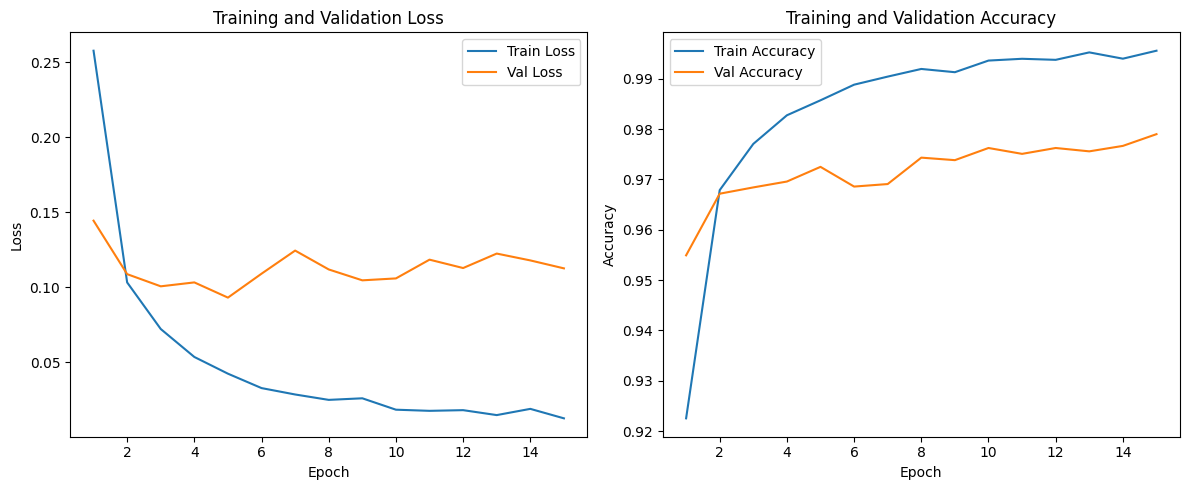

In [4]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), train_losses, label='Train Loss')
plt.plot(range(1, epochs + 1), val_losses, label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), train_accuracies, label='Train Accuracy')
plt.plot(range(1, epochs + 1), val_accuracies, label='Val Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.tight_layout()
plt.savefig('learning_curves.png')
plt.show()

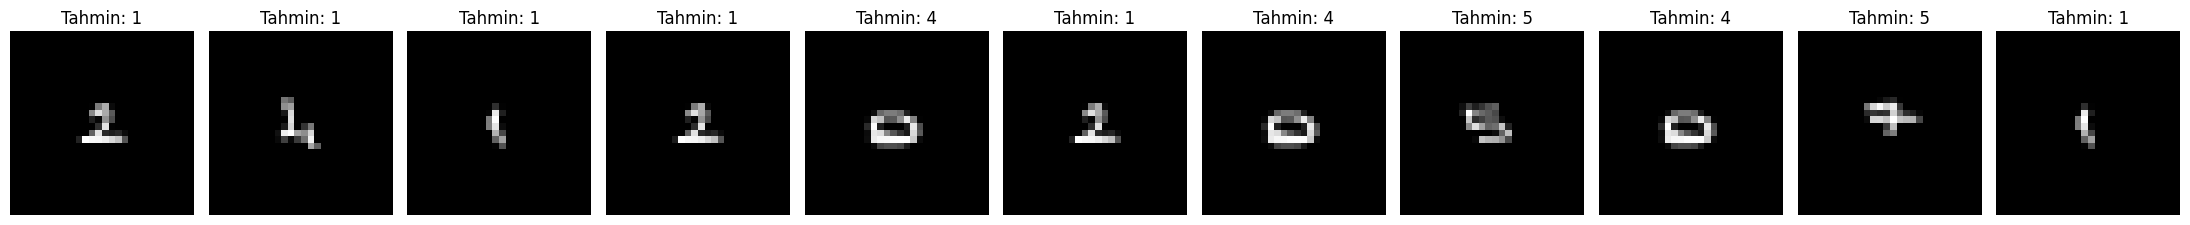

In [8]:
import numpy as np
import cv2

custom_images_folder = './my_digits'
image_files = sorted([f for f in os.listdir(custom_images_folder) if f.endswith(('.jpg', '.jpeg', '.png'))])

transform_custom = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

model.eval()

plt.figure(figsize=(len(image_files) * 2, 3))

for idx, file_name in enumerate(image_files):
    img_path = os.path.join(custom_images_folder, file_name)

    img = Image.open(img_path).convert('L')
    img_np = np.array(img)

    _, thresh = cv2.threshold(img_np, 120, 255, cv2.THRESH_BINARY_INV)

    kernel = np.ones((5, 5), np.uint8)
    dilated = cv2.dilate(thresh, kernel, iterations=2)

    resized = cv2.resize(dilated, (28, 28), interpolation=cv2.INTER_AREA)

    tensor_img = transform_custom(resized).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(tensor_img)
        prediction = torch.argmax(output, dim=1).item()

    plt.subplot(1, len(image_files), idx + 1)
    plt.imshow(resized, cmap='gray')
    plt.title(f"Tahmin: {prediction}")
    plt.axis('off')

plt.tight_layout()
plt.savefig('my_student_id_predictions_fixed.png')
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

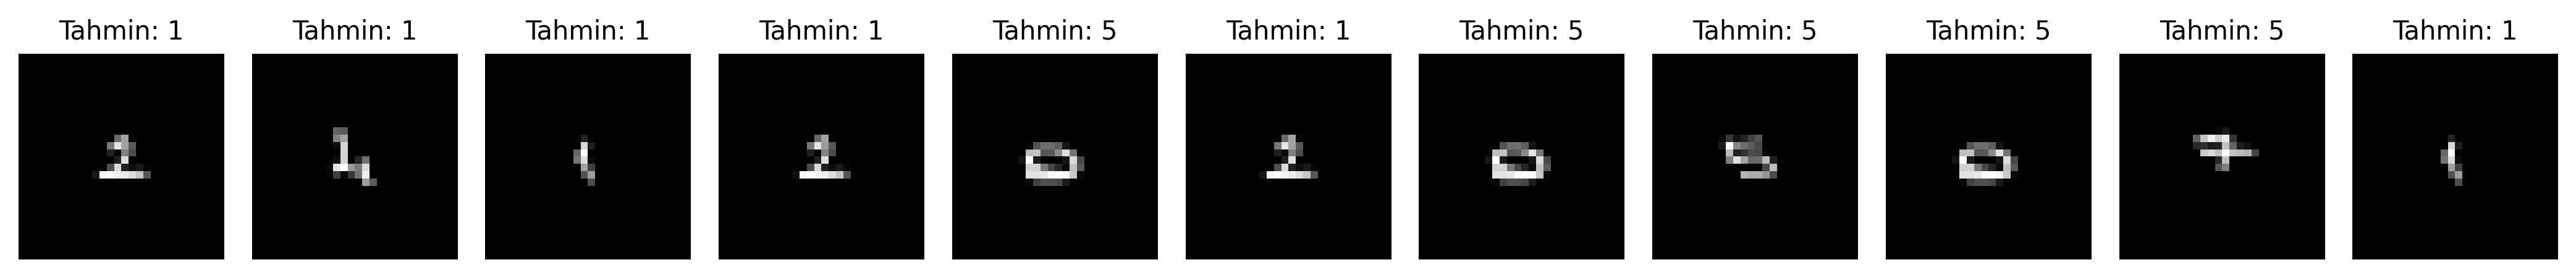

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [12]:
import numpy as np
import cv2
from google.colab import files

custom_images_folder = './my_digits'
image_files = sorted([f for f in os.listdir(custom_images_folder) if f.endswith(('.jpg', '.jpeg', '.png'))])

transform_custom = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

model.eval()

plt.figure(figsize=(14, 2.5), dpi=300)

for idx, file_name in enumerate(image_files):
    img_path = os.path.join(custom_images_folder, file_name)
    img = Image.open(img_path).convert('L')

    img_np = np.array(img)
    _, thresh = cv2.threshold(img_np, 120, 255, cv2.THRESH_BINARY_INV)

    kernel = np.ones((8, 8), np.uint8)
    dilated = cv2.dilate(thresh, kernel, iterations=1)

    resized = cv2.resize(dilated, (28, 28), interpolation=cv2.INTER_AREA)

    tensor_img = transform_custom(resized).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(tensor_img)
        prediction = torch.argmax(output, dim=1).item()

    plt.subplot(1, len(image_files), idx + 1)
    plt.imshow(resized, cmap='gray', interpolation='nearest')
    plt.title(f"Tahmin: {prediction}", fontsize=10)
    plt.axis('off')

plt.tight_layout()
output_filename = 'ogrenci_numarasi_tahminler.png'
plt.savefig(output_filename, bbox_inches='tight', dpi=300)
plt.show()

files.download(output_filename)